# 08 — Diagnosis: kenapa akurasi rendah & apa yang realistis menaikkannya

> **Analisis diagnostik pada PILOT ±20 % dataset (200 dari 1.002 subjek).** Tidak ada model yang dipilih atau dikunci dari analisis
> ini, konfigurasi terkunci tidak diubah, dan test held-out (149 subjek) tidak disentuh. Model yang dipakai hanya LogReg
> (fenotipik & ROI) dengan pipeline yang sama persis dengan runner (preprocessing di-fit di train fold; ComBat kovariat usia & jenis kelamin).

Tiga pertanyaan:
1. **Apakah lebih banyak data akan membantu?** → *learning curve* (25–100 % data latih tiap fold).
2. **Kenapa sinyal lemah?** → dekomposisi variansi fitur ROI: berapa yang dijelaskan **site** vs **diagnosis**, dan besar efek diagnosis (Cohen's d).
3. **Apakah akurasi sekarang nyata di atas kebetulan?** → *permutation test* (label diacak di dalam tiap site).

In [1]:
from pathlib import Path
RESULT_DIR = Path(r"C:\ta_local\results\pilot200_v2")
SUBSET = "pilot200"
N_PERM = 200          # permutation test
N_REPEAT = 10         # pengulangan subsampel learning curve
FRACS = [0.25, 0.5, 0.75, 1.0]

In [2]:
import sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pilot_common.py").exists())
sys.path.insert(0, str(PROJECT / "src"))
import pilot_common as pc, pilot_models as pm
from sklearn.metrics import roc_auc_score

CFG = json.loads((RESULT_DIR / "config.json").read_text(encoding="utf-8"))["config"]
SPL = {int(k): {p: np.asarray(v) for p, v in s.items()} for k, s in json.loads((RESULT_DIR / "splits.json").read_text(encoding="utf-8")).items()}
cohort, _ = pc.load_cohort(SUBSET)
pheno, _ = pc.load_pheno(cohort)
FEAT = pc.missing_report(cohort, pheno).query("used").feature.tolist()
ROI = pd.read_csv(RESULT_DIR / "cache" / "roi" / "roi_features.csv").set_index("SUB_ID").loc[cohort.SUB_ID]
lab = cohort.set_index("SUB_ID")["label"]; site = cohort.set_index("SUB_ID")["SITE_ID"]
COV = pheno[["AGE_AT_SCAN", "SEX"]]
OUTF = RESULT_DIR / "report" / "figures"; OUTT = RESULT_DIR / "report" / "tables"
STYLE = [{"selector": "th", "props": "background:#1c5cab;color:white;text-align:left;padding:6px 8px;font-size:12px"},
         {"selector": "td", "props": "padding:6px 8px;font-size:12px;border-bottom:1px solid #e5e5e5"}]
def show(df): display(df.style.hide(axis="index").set_table_styles(STYLE))

def fit_predict(kind, tr, te, y_tr):
    # sama dengan runner: preprocessing di-fit di train, LogReg (C=1, class_weight balanced)
    hp = CFG["models"]["logreg"]
    if kind == "pheno":
        pre = pm.TabPre("pheno", FEAT).fit(pheno.loc[tr]); Ztr, Zte = pre.transform(pheno.loc[tr]), pre.transform(pheno.loc[te])
    else:
        c = lambda ids: COV.loc[ids].reset_index(drop=True)
        pre = pm.TabPre("roi", list(ROI.columns), combat=True).fit(ROI.loc[tr], site.loc[tr].to_numpy(), c(tr))
        Ztr = pre.transform(ROI.loc[tr], site.loc[tr].to_numpy(), c(tr)); Zte = pre.transform(ROI.loc[te], site.loc[te].to_numpy(), c(te))
    return pm.fit_tab_model("logreg", hp, Ztr, y_tr, 0)(Zte)

def cv_auc(kind, y=lab, frac=1.0, rng=None):
    P, Y = [], []
    for k, s in SPL.items():
        T = np.concatenate([s["inner_train"], s["inner_val"]])
        if frac < 1:
            yt = y.loc[T].to_numpy()
            T = np.concatenate([rng.choice(T[yt == c], max(2, int(round(frac * (yt == c).sum()))), replace=False) for c in (0, 1)])
        P.append(fit_predict(kind, T, s["test"], y.loc[T].to_numpy())); Y.append(y.loc[s["test"]].to_numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    return roc_auc_score(Y, P), P, Y

def ba(Y, P): return 0.5 * (((P >= 0.5) & (Y == 1)).sum() / (Y == 1).sum() + ((P < 0.5) & (Y == 0)).sum() / (Y == 0).sum())
# kontrol: pada 100 % data, hasil harus sama dengan unit runner
for kind, unit in (("pheno", "logreg"), ("roi", "roi_logreg_cb")):
    auc, P, Y = cv_auc(kind)
    ref = pd.concat([pd.read_csv(pc.unit_dir(RESULT_DIR, f"{unit}:{k}") / "preds.csv") for k in SPL]).query("part == 'test'")
    print(f"{unit}: AUC {auc:.4f} | runner {roc_auc_score(ref.label, ref.prob):.4f}")
    assert abs(auc - roc_auc_score(ref.label, ref.prob)) < 1e-6, "reproduksi tidak sama dengan runner"
print("Kontrol lulus: pipeline analisis identik dengan runner.")

logreg: AUC 0.5643 | runner 0.5643


roi_logreg_cb: AUC 0.5464 | runner 0.5464
Kontrol lulus: pipeline analisis identik dengan runner.


## 1. Learning curve — apakah lebih banyak data membantu?

Tiap fold, data latih (±160 subjek) disubsampel 25/50/75/100 % (stratifikasi label, diulang 10×), lalu dievaluasi pada test fold
yang sama. Garis = rata-rata AUC pooled, bayangan = ±SD antar pengulangan. Bila kurva **masih naik** di 100 %, menambah data
(data penuh ±4×) kemungkinan besar menaikkan akurasi.

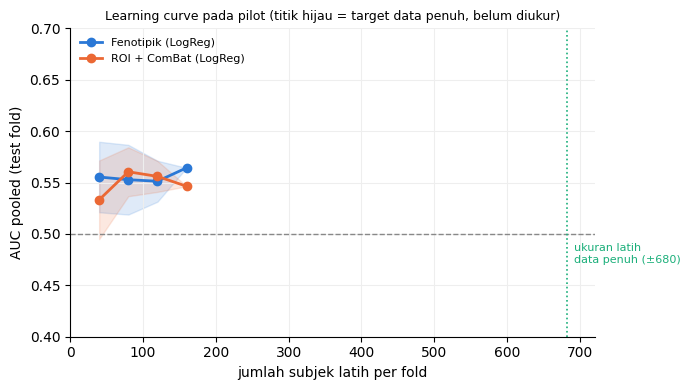

fitur,fraksi,n latih/fold,AUC (mean ± SD),BA
Fenotipik (LogReg),0.250000,40,0.555 ± 0.034,0.539000
Fenotipik (LogReg),0.500000,80,0.553 ± 0.034,0.532000
Fenotipik (LogReg),0.750000,120,0.551 ± 0.020,0.544000
Fenotipik (LogReg),1.000000,160,0.564,0.558000
ROI + ComBat (LogReg),0.250000,40,0.533 ± 0.038,0.535000
ROI + ComBat (LogReg),0.500000,80,0.560 ± 0.024,0.545000
ROI + ComBat (LogReg),0.750000,120,0.556 ± 0.015,0.542000
ROI + ComBat (LogReg),1.000000,160,0.546,0.550000


(9 s) Kenaikan AUC per penggandaan data latih: Fenotipik (LogReg): +0.003; ROI + ComBat (LogReg): +0.008


In [3]:
t0 = time.time(); rows = []
for kind, name in (("pheno", "Fenotipik (LogReg)"), ("roi", "ROI + ComBat (LogReg)")):
    for f in FRACS:
        reps = [1] if f == 1.0 else range(N_REPEAT)
        for r in reps:
            auc, P, Y = cv_auc(kind, frac=f, rng=np.random.default_rng(1000 + r))
            rows.append({"fitur": name, "fraksi": f, "n latih/fold": int(round(f * 160)), "AUC": auc, "BA": ba(Y, P)})
LC = pd.DataFrame(rows)
S = LC.groupby(["fitur", "fraksi", "n latih/fold"]).agg(AUC=("AUC", "mean"), AUC_sd=("AUC", "std"), BA=("BA", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(7, 4))
for (name, g), c in zip(S.groupby("fitur"), ["#2a78d6", "#eb6834"]):
    ax.plot(g["n latih/fold"], g.AUC, "o-", color=c, lw=2, label=name)
    ax.fill_between(g["n latih/fold"], g.AUC - g.AUC_sd.fillna(0), g.AUC + g.AUC_sd.fillna(0), color=c, alpha=0.15)
ax.axhline(0.5, color="#888", ls="--", lw=1); ax.axvline(160 * 853 / 200, color="#1baf7a", ls=":", lw=1.2)
ax.text(160 * 853 / 200, 0.47, "  ukuran latih\n  data penuh (±680)", color="#1baf7a", fontsize=8, va="bottom")
ax.set_xlim(0, 720); ax.set_ylim(0.4, 0.7); ax.set_xlabel("jumlah subjek latih per fold"); ax.set_ylabel("AUC pooled (test fold)")
ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#eee")
ax.set_title("Learning curve pada pilot (titik hijau = target data penuh, belum diukur)", fontsize=9); fig.tight_layout()
fig.savefig(OUTF / "08_learning_curve.png", dpi=150, bbox_inches="tight"); plt.show()
S["AUC (mean ± SD)"] = [f"{a:.3f} ± {s:.3f}" if s == s else f"{a:.3f}" for a, s in zip(S.AUC, S.AUC_sd)]
show(S[["fitur", "fraksi", "n latih/fold", "AUC (mean ± SD)", "BA"]].round(3)); LC.to_csv(OUTT / "08_learning_curve.csv", index=False)
slope = {name: np.polyfit(np.log(g["n latih/fold"]), g.AUC, 1)[0] for name, g in S.groupby("fitur")}
print(f"({time.time() - t0:.0f} s) Kenaikan AUC per penggandaan data latih: " + "; ".join(f"{k}: {v * np.log(2):+.3f}" for k, v in slope.items()))

## 2. Kenapa sinyal lemah? Site vs diagnosis

Untuk tiap fitur ROI (mean & SD intensitas 111 region), model linear `fitur ~ site + diagnosis + usia + jenis kelamin` pada 200 subjek
(deskriptif, tidak dipakai untuk memilih fitur). **η² parsial** = porsi variansi yang dijelaskan site atau diagnosis.
**Cohen's d** = beda ASD–TD setelah dikoreksi site, usia, dan jenis kelamin. Bila diagnosis hanya mungkin ditebak secara kebetulan,
sekitar 5 % fitur akan "signifikan" pada p < 0,05.

Ukuran,Nilai,Arti
Median η² parsial SITE,0.417,site menjelaskan ±42 % variansi fitur ROI
Median η² parsial DIAGNOSIS,0.0038,diagnosis menjelaskan ±0.38 % variansi
Rasio site : diagnosis (median),109 : 1,efek site jauh lebih besar dari efek ASD
"Fitur dengan p(diagnosis) < 0,05",18 / 222 (8.1 %),sedikit di atas kebetulan (5 %)
"Lolos koreksi FDR (q < 0,05)",0,fitur yang bertahan setelah koreksi perbandingan berganda
|Cohen's d| median / maks,0.12 / 0.52,"efek kecil (d < 0,2 = sangat kecil; 0,5 = sedang)"


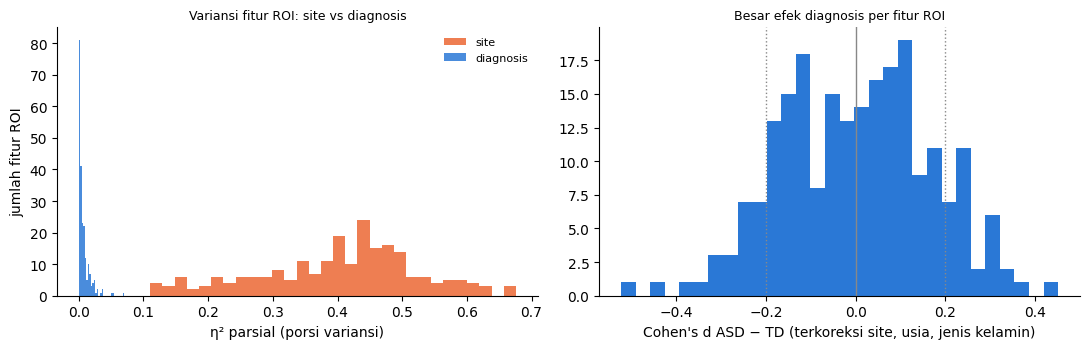

**Fitur fenotipik: beda ASD vs TD**

fitur fenotipik,ASD (mean),TD (mean),Cohen's d,p (t-test)
AGE_AT_SCAN,16.890000,16.980000,-0.010000,0.937000
SEX,1.120000,1.150000,-0.110000,0.452000
FIQ,105.880000,111.510000,-0.370000,0.013000
volume_mask_ml,1471.590000,1439.470000,0.230000,0.101000


In [4]:
from scipy import stats
Xr = ROI.copy(); Xr = Xr.fillna(Xr.median())
site_d = pd.get_dummies(site.loc[Xr.index], drop_first=True).astype(float).to_numpy()
age = COV.loc[Xr.index, "AGE_AT_SCAN"].to_numpy(float); sex = COV.loc[Xr.index, "SEX"].to_numpy(float)
dx = lab.loc[Xr.index].to_numpy(float); one = np.ones(len(dx))
def rss(A, y): b, *_ = np.linalg.lstsq(A, y, rcond=None); r = y - A @ b; return r @ r
full = np.column_stack([one, site_d, dx, age, sex]); no_site = np.column_stack([one, dx, age, sex]); no_dx = np.column_stack([one, site_d, age, sex])
rows = []
for col in Xr.columns:
    y = Xr[col].to_numpy(float); rf = rss(full, y)
    eta_site = (rss(no_site, y) - rf) / (rss(no_site, y) - rf + rf); eta_dx = (rss(no_dx, y) - rf) / (rss(no_dx, y) - rf + rf)
    F = (rss(no_dx, y) - rf) / (rf / (len(y) - full.shape[1])); p = stats.f.sf(F, 1, len(y) - full.shape[1])
    b, *_ = np.linalg.lstsq(no_dx, y, rcond=None); res = y - no_dx @ b
    d = (res[dx == 1].mean() - res[dx == 0].mean()) / res.std(ddof=1)
    rows.append({"fitur": col, "eta2_site": eta_site, "eta2_dx": eta_dx, "p_dx": p, "d_dx": d})
V = pd.DataFrame(rows); V.to_csv(OUTT / "08_variansi_site_vs_dx.csv", index=False)
summ = pd.DataFrame([
    ("Median η² parsial SITE", f"{V.eta2_site.median():.3f}", f"site menjelaskan ±{100 * V.eta2_site.median():.0f} % variansi fitur ROI"),
    ("Median η² parsial DIAGNOSIS", f"{V.eta2_dx.median():.4f}", f"diagnosis menjelaskan ±{100 * V.eta2_dx.median():.2f} % variansi"),
    ("Rasio site : diagnosis (median)", f"{V.eta2_site.median() / V.eta2_dx.median():.0f} : 1", "efek site jauh lebih besar dari efek ASD"),
    ("Fitur dengan p(diagnosis) < 0,05", f"{(V.p_dx < 0.05).sum()} / {len(V)} ({100 * (V.p_dx < 0.05).mean():.1f} %)",
     "≈ 5 % = sejauh yang diharapkan secara kebetulan" if (V.p_dx < 0.05).mean() < 0.08 else "sedikit di atas kebetulan (5 %)"),
    ("Lolos koreksi FDR (q < 0,05)", f"{int((stats.false_discovery_control(V.p_dx) < 0.05).sum())}", "fitur yang bertahan setelah koreksi perbandingan berganda"),
    ("|Cohen's d| median / maks", f"{V.d_dx.abs().median():.2f} / {V.d_dx.abs().max():.2f}", "efek kecil (d < 0,2 = sangat kecil; 0,5 = sedang)"),
], columns=["Ukuran", "Nilai", "Arti"])
show(summ)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(V.eta2_site, bins=30, color="#eb6834", alpha=0.85, label="site"); axes[0].hist(V.eta2_dx, bins=30, color="#2a78d6", alpha=0.85, label="diagnosis")
axes[0].set_xlabel("η² parsial (porsi variansi)"); axes[0].set_ylabel("jumlah fitur ROI"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Variansi fitur ROI: site vs diagnosis", fontsize=9)
axes[1].hist(V.d_dx, bins=30, color="#2a78d6"); axes[1].axvline(0, color="#888", lw=1)
for v in (-0.2, 0.2): axes[1].axvline(v, color="#888", ls=":", lw=1)
axes[1].set_xlabel("Cohen's d ASD − TD (terkoreksi site, usia, jenis kelamin)"); axes[1].set_title("Besar efek diagnosis per fitur ROI", fontsize=9)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUTF / "08_site_vs_diagnosis.png", dpi=150, bbox_inches="tight"); plt.show()

ph = pheno[FEAT].join(lab); rows = []
for c in FEAT:
    a, b = ph.loc[ph.label == 1, c].dropna(), ph.loc[ph.label == 0, c].dropna()
    sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    rows.append({"fitur fenotipik": c, "ASD (mean)": round(a.mean(), 2), "TD (mean)": round(b.mean(), 2),
                 "Cohen's d": round((a.mean() - b.mean()) / sd, 2), "p (t-test)": round(stats.ttest_ind(a, b).pvalue, 3)})
display(Markdown("**Fitur fenotipik: beda ASD vs TD**")); show(pd.DataFrame(rows))

## 3. Permutation test — apakah AUC sekarang nyata?

Label ASD/TD diacak **di dalam tiap site** (struktur site dipertahankan) sebanyak N kali; seluruh CV 5 fold diulang dengan label acak.
p-value = proporsi AUC acak ≥ AUC asli. p < 0,05 → model menangkap sinyal yang nyata walaupun kecil.

model,AUC asli,AUC acak (mean ± SD),persentil 95 % acak,p-value,kesimpulan
Fenotipik (LogReg),0.564000,0.476 ± 0.056,0.558000,0.044800,di atas kebetulan
ROI + ComBat (LogReg),0.546000,0.511 ± 0.055,0.610000,0.253700,belum terbukti di atas kebetulan


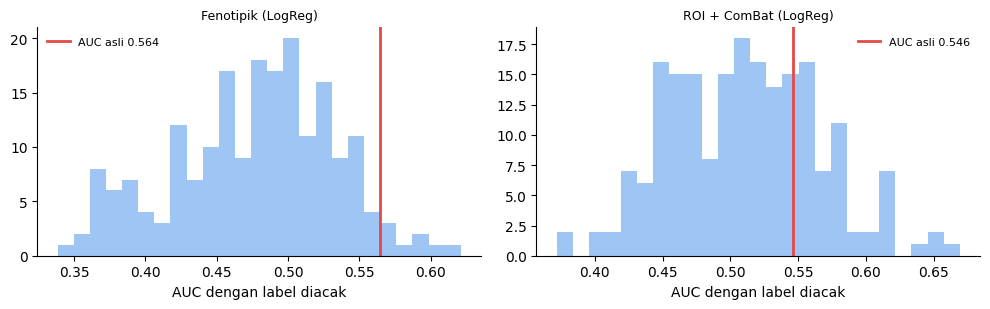

(58 s)


In [5]:
t0 = time.time(); rows = []; nulls = {}
for kind, name in (("pheno", "Fenotipik (LogReg)"), ("roi", "ROI + ComBat (LogReg)")):
    obs, _, _ = cv_auc(kind)
    rng = np.random.default_rng(42); null = []
    for i in range(N_PERM):
        yp = lab.copy()
        for s_, idx in cohort.groupby("SITE_ID").SUB_ID:
            yp.loc[idx.to_numpy()] = rng.permutation(lab.loc[idx.to_numpy()].to_numpy())
        null.append(cv_auc(kind, y=yp)[0])
    null = np.array(null); nulls[name] = (obs, null)
    rows.append({"model": name, "AUC asli": round(obs, 3), "AUC acak (mean ± SD)": f"{null.mean():.3f} ± {null.std():.3f}",
                 "persentil 95 % acak": round(np.percentile(null, 95), 3), "p-value": round((1 + (null >= obs).sum()) / (1 + N_PERM), 4),
                 "kesimpulan": "di atas kebetulan" if (1 + (null >= obs).sum()) / (1 + N_PERM) < 0.05 else "belum terbukti di atas kebetulan"})
PT = pd.DataFrame(rows); show(PT); PT.to_csv(OUTT / "08_permutation_test.csv", index=False)
fig, axes = plt.subplots(1, len(nulls), figsize=(10, 3.2))
for ax, (name, (obs, null)) in zip(axes, nulls.items()):
    ax.hist(null, bins=25, color="#9ec5f4"); ax.axvline(obs, color="#e34948", lw=2, label=f"AUC asli {obs:.3f}")
    ax.set_title(name, fontsize=9); ax.set_xlabel("AUC dengan label diacak"); ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUTF / "08_permutation_test.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"({time.time() - t0:.0f} s)")

## 4. Kesimpulan otomatis: kenapa rendah & apa yang realistis

In [6]:
lc = {name: g.sort_values("fraksi") for name, g in S.groupby("fitur")}
gain = {k: g.AUC.iloc[-1] - g.AUC.iloc[0] for k, g in lc.items()}
pv = dict(zip(PT.model, PT["p-value"]))
K = pd.DataFrame([
    ("Sinyal diagnosis di fitur memang kecil",
     f"Diagnosis menjelaskan ±{100 * V.eta2_dx.median():.2f} % variansi fitur ROI (site ±{100 * V.eta2_site.median():.0f} %); "
     f"|d| median {V.d_dx.abs().median():.2f}; {100 * (V.p_dx < 0.05).mean():.1f} % fitur p < 0,05.",
     "Batas atas akurasi dari fitur intensitas ROI rendah; perlu fitur yang lebih sensitif (morfometri: volume/ketebalan)."),
    ("Efek site mendominasi",
     f"Variansi karena site ±{V.eta2_site.median() / V.eta2_dx.median():.0f}× variansi karena diagnosis.",
     "Harmonisasi (ComBat) wajib; evaluasi lintas site (LOSO) perlu untuk klaim generalisasi."),
    ("Apakah menambah data membantu?",
     "; ".join(f"{k}: AUC {g.AUC.iloc[0]:.3f} ± {g.AUC_sd.iloc[0]:.3f} (25 %) → {g.AUC.iloc[-1]:.3f} (100 %)" for k, g in lc.items()),
     "Kurva " + ("naik melebihi noise → data penuh (±4×) kemungkinan membantu" if
                 all(gain[k] > 2 * g.AUC_sd.iloc[0] for k, g in lc.items()) else
                 "DATAR dalam batas noise pada rentang 40–160 subjek → menambah data saja kemungkinan hanya memberi kenaikan kecil "
                 "untuk fitur ini; pengungkit utama adalah fitur yang lebih informatif. Tetap perlu dicek di data penuh.")),
    ("Apakah sinyal sekarang nyata?", "; ".join(f"{k}: p = {v}" for k, v in pv.items()),
     "p < 0,05 → sinyal nyata walau kecil; p ≥ 0,05 → pada n = 200 belum bisa dibedakan dari kebetulan."),
], columns=["Penyebab / pertanyaan", "Bukti dari pilot", "Implikasi"])
display(K.style.hide(axis="index").set_table_styles(STYLE).set_properties(**{"white-space": "normal"}))
K.to_csv(OUTT / "08_kesimpulan.csv", index=False)

Penyebab / pertanyaan,Bukti dari pilot,Implikasi
Sinyal diagnosis di fitur memang kecil,"Diagnosis menjelaskan ±0.38 % variansi fitur ROI (site ±42 %); |d| median 0.12; 8.1 % fitur p < 0,05.",Batas atas akurasi dari fitur intensitas ROI rendah; perlu fitur yang lebih sensitif (morfometri: volume/ketebalan).
Efek site mendominasi,Variansi karena site ±109× variansi karena diagnosis.,Harmonisasi (ComBat) wajib; evaluasi lintas site (LOSO) perlu untuk klaim generalisasi.
Apakah menambah data membantu?,Fenotipik (LogReg): AUC 0.555 ± 0.034 (25 %) → 0.564 (100 %); ROI + ComBat (LogReg): AUC 0.533 ± 0.038 (25 %) → 0.546 (100 %),Kurva DATAR dalam batas noise pada rentang 40–160 subjek → menambah data saja kemungkinan hanya memberi kenaikan kecil untuk fitur ini; pengungkit utama adalah fitur yang lebih informatif. Tetap perlu dicek di data penuh.
Apakah sinyal sekarang nyata?,Fenotipik (LogReg): p = 0.0448; ROI + ComBat (LogReg): p = 0.2537,"p < 0,05 → sinyal nyata walau kecil; p ≥ 0,05 → pada n = 200 belum bisa dibedakan dari kebetulan."
